<a href="https://colab.research.google.com/github/kathirkanth-codes/decoupled-surface-code-threshold/blob/main/decoupled_sweeper.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1: Running simulations across 3 gate noise settings (10,000 shots each)...
SUCCESS: 'advanced_decoupled_phase_data.csv' saved to your workspace side folder!
SUCCESS: Saved visual asset 'threshold_plot_Clean_Gates_0.1pc.png' to your side panel folder!


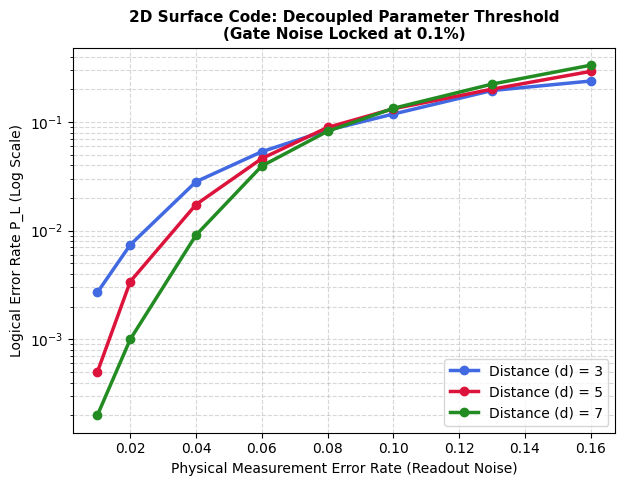

SUCCESS: Saved visual asset 'threshold_plot_Moderate_Gates_0.5pc.png' to your side panel folder!


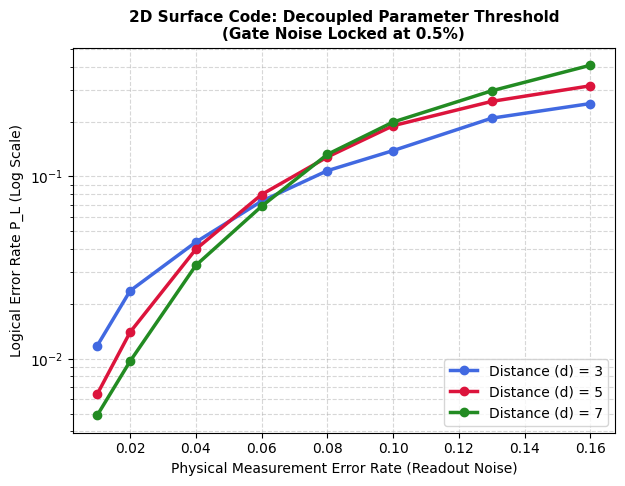

SUCCESS: Saved visual asset 'threshold_plot_Noisy_Gates_1.0pc.png' to your side panel folder!


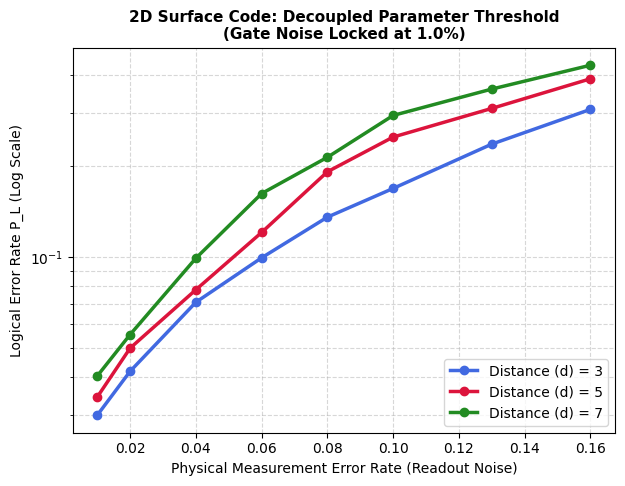

In [6]:
# 1. Install required quantum libraries
!pip install stim sinter pymatching pandas matplotlib

import stim
import sinter
import pandas as pd
import matplotlib.pyplot as plt

# 2. Setup the experiment parameters
distances = [3, 5, 7]
measurement_sweep = [0.01, 0.02, 0.04, 0.06, 0.08, 0.10, 0.13, 0.16]
# We map the text scenarios to their clear numerical percentages
gate_scenarios = {'Clean_Gates_0.1pc': 0.001, 'Moderate_Gates_0.5pc': 0.005, 'Noisy_Gates_1.0pc': 0.010}

all_tasks = []
for scenario_name, fixed_gate_p in gate_scenarios.items():
    for d in distances:
        for m_p in measurement_sweep:
            circuit = stim.Circuit.generated(
                code_task="surface_code:rotated_memory_z",
                distance=d,
                rounds=d,
                after_clifford_depolarization=fixed_gate_p,
                after_reset_flip_probability=m_p
            )
            all_tasks.append(sinter.Task(
                circuit=circuit,
                json_metadata={'scenario': scenario_name, 'd': d, 'gate_p': fixed_gate_p, 'meas_p': m_p}
            ))

print("Step 1: Running simulations across 3 gate noise settings (10,000 shots each)...")
stats = sinter.collect(
    num_workers=4, max_shots=10000, max_errors=300, tasks=all_tasks, decoders=['pymatching']
)

# 3. Compile and save the complete dataset to CSV
parsed_rows = []
for s in stats:
    parsed_rows.append({
        'Scenario': s.json_metadata['scenario'],
        'Distance': s.json_metadata['d'],
        'Gate_Noise': s.json_metadata['gate_p'],
        'Measurement_Noise': s.json_metadata['meas_p'],
        'Shots': s.shots,
        'Logical_Errors': s.errors,
        'Logical_Error_Rate': s.errors / s.shots
    })

df = pd.DataFrame(parsed_rows)
df.to_csv('advanced_decoupled_phase_data.csv', index=False)
print("SUCCESS: 'advanced_decoupled_phase_data.csv' saved to your workspace side folder!")

# 4. FIXED GRAPH GENERATION: Loop over all scenarios to draw separate charts!
colors = {3: 'royalblue', 5: 'crimson', 7: 'forestgreen'}

for scenario_name, fixed_gate_p in gate_scenarios.items():
    plt.figure(figsize=(7, 5))

    # Filter the spreadsheet rows for the current scenario in the loop
    scenario_df = df[df['Gate_Noise'] == fixed_gate_p]

    for d_val in distances:
        plot_df = scenario_df[scenario_df['Distance'] == d_val].sort_values(by='Measurement_Noise')
        plt.plot(plot_df['Measurement_Noise'], plot_df['Logical_Error_Rate'], marker='o',
                 color=colors[d_val], linewidth=2.5, label=f"Distance (d) = {d_val}")

    plt.title(f"2D Surface Code: Decoupled Parameter Threshold\n(Gate Noise Locked at {fixed_gate_p * 100}%)", fontsize=11, fontweight='bold')
    plt.xlabel("Physical Measurement Error Rate (Readout Noise)", fontsize=10)
    plt.ylabel("Logical Error Rate P_L (Log Scale)", fontsize=10)
    plt.yscale('log')
    plt.grid(True, which="both", ls="--", alpha=0.5)
    plt.legend(loc="lower right")

    # Save each graph independently using its distinct name format
    filename = f"threshold_plot_{scenario_name}.png"
    plt.savefig(filename, bbox_inches='tight', dpi=150)
    print(f"SUCCESS: Saved visual asset '{filename}' to your side panel folder!")
    plt.show()